# 04 · Figures: a visual tour of the results

Notebook 03 gives the numbers; this notebook shows **what is behind them**. Most plots are taken from the group
notebook `bucked_based_eval.ipynb` and adapted to the final setup:

- **Models:** the matched models from notebooks 02a/02b (same 38 training trajectories, best-validation checkpoint).
  Plots of averages use the **mean over the 3 seeds**. Plots of single predictions use **seed 0**.
- **Buckets:** made from the measure chosen in `BUCKET_MEASURE` below. The default is **total variation of the
  128-point input** (our primary measure). Set it to `"sharpness"` or `"max slope"` to redraw every figure with the
  other buckets.
- **Names:** the "identity" baseline is called **persistence** (prediction = input), as in the report.
- Nothing is saved to disk; the figures are only shown here.

| # | Figure | Source | What it shows |
|---|---|---|---|
| A | Roughness of every input, typical input per bucket | `bucked_based_eval` | How the buckets are formed |
| B | Error table and FNO-vs-CNN "wins" | `bucked_based_eval` | The numbers per bucket and grid |
| C | Error growth with resolution | `bucked_based_eval` (+ difference panel) | The main effect at a glance |
| D | Error per bucket vs persistence | `bucked_based_eval` | Accuracy and usefulness together |
| E | One typical prediction per bucket | `bucked_based_eval` | What the models actually output |
| F | Prediction errors along x | `bucked_based_eval` | *Where* the errors are |
| G | Error of every input vs its roughness | `bucked_based_eval` | The same result without bucket edges |
| H | Where the FNO's error sits | new | For smooth inputs, half of it is at the domain edges |
| I | Error spectrum at 512 points | new | Part 2: spurious vs recovered fine-scale detail |
| J | Zoom on one rough front, FNO trained at 32 points | new | Part 2: the FNO fills in detail it never saw |

Every plot from `bucked_based_eval` is kept. Its two bucket-file cells are not figures; here the buckets are made in
memory instead of being written to `.npz` files.

In [1]:
BUCKET_MEASURE = "total variation"      # "total variation" (primary), "sharpness" or "max slope"
EXAMPLE_SEED = 0                        # which seed's predictions to draw in figures E, F, J

In [2]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

DATA, CKPT = os.path.join("..", "data"), "checkpoints"
RESOLUTIONS = [128, 256, 512]
BUCKETS = ["smooth", "medium", "rough"]

# colours: models get fixed hues, buckets a light -> dark blue ramp
COLORS = {"FNO": "#2a78d6", "CNN": "#eb6834", "Persistence": "#9a9a9a"}
BUCKET_COLORS = {"smooth": "#86b6ef", "medium": "#2a78d6", "rough": "#104281"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "legend.frameon": False})

def log_axis(axis):
    # readable log-scale ticks (1, 2, 5, 10, ...) as in bucked_based_eval
    axis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(NullFormatter())

## Setup: models, data, buckets, predictions

The model classes are **copied unchanged from notebooks 02a/02b**.

In [3]:
class GridLockedCNN(nn.Module):
    def __init__(self, hidden=64, kernel_size=3, num_layers=4):
        super().__init__()
        conv = lambda a, b: nn.Conv1d(a, b, kernel_size, padding=kernel_size // 2, padding_mode="circular")
        layers = [conv(1, hidden), nn.ReLU()]
        for _ in range(num_layers - 1):
            layers += [conv(hidden, hidden), nn.ReLU()]
        layers.append(conv(hidden, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, u):
        u = u[:, None, :]
        return (u + self.net(u))[:, 0, :]

def make_input(u):
    batch, n = u.shape
    x = torch.linspace(0, 1, n + 1, device=u.device)[:-1]
    return torch.stack([u, x.expand(batch, n)], dim=-1)

class SpectralConv1d(nn.Module):
    def __init__(self, cin, cout, modes):
        super().__init__()
        self.modes = modes
        self.weights = nn.Parameter(1 / (cin * cout) * torch.randn(cin, cout, modes, dtype=torch.cfloat))
    def forward(self, x):
        b, _, n = x.shape
        xf = torch.fft.rfft(x)
        out = torch.zeros(b, self.weights.shape[1], n // 2 + 1, dtype=torch.cfloat)
        k = min(self.modes, n // 2 + 1)
        out[:, :, :k] = torch.einsum("bix,iox->box", xf[:, :, :k], self.weights[:, :, :k])
        return torch.fft.irfft(out, n=n)

class FNO1d(nn.Module):
    def __init__(self, modes=64, width=64, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)
        self.spec = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(n_layers)])
        self.w = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])
        self.proj = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))
    def forward(self, u):
        x = self.lift(make_input(u)).permute(0, 2, 1)
        for f, w in zip(self.spec, self.w):
            x = nn.functional.gelu(f(x) + w(x))
        return self.proj(x.permute(0, 2, 1)).squeeze(-1)

def load_model(name, n_train, seed):
    ck = torch.load(os.path.join(CKPT, f"{name}_train{n_train}_seed{seed}.pt"), map_location="cpu", weights_only=False)
    model = (GridLockedCNN if name == "cnn" else FNO1d)(**ck["config"])
    model.load_state_dict(ck["state"]); model.eval()
    return model

def predict(model, u):
    with torch.no_grad():
        return model(torch.tensor(u, dtype=torch.float32)).numpy()

def rel_l2(pred, true):
    return np.linalg.norm(pred - true, axis=1) / np.linalg.norm(true, axis=1)

In [4]:
# evaluation data on every grid (all exact subsamples of the 512-point data)
d512 = np.load(os.path.join(DATA, "eval_512.npz"))
GRIDS = [32, 64, 128, 256, 512]
u_now = {N: d512["field"][:, ::512 // N].astype(np.float32) for N in GRIDS}
u_next = {N: d512["target"][:, ::512 // N].astype(np.float32) for N in GRIDS}

# the three roughness measures, all on the 128-point input (notebook 01, section 2)
u = u_now[128].astype(np.float64)
MEASURES = {
    "total variation": np.abs(np.roll(u, -1, 1) - u).sum(1),
    "sharpness": np.sqrt((((np.roll(u, -1, 1) - np.roll(u, 1, 1)) / (2 / 128)) ** 2).mean(1))
                 / np.sqrt(((u - u.mean(1, keepdims=True)) ** 2).mean(1)),
    "max slope": np.abs(np.roll(u, -1, 1) - u).max(1),
}
score = MEASURES[BUCKET_MEASURE]
order = np.argsort(score, kind="stable")
idx = {b: np.sort(i) for b, i in zip(BUCKETS, np.array_split(order, 3))}     # example indices per bucket
label = np.empty(60, dtype=int)
for k, b in enumerate(BUCKETS):
    label[idx[b]] = k
edges = [(score[idx[lo]].max() + score[idx[hi]].min()) / 2 for lo, hi in zip(BUCKETS[:-1], BUCKETS[1:])]
print(f"buckets from: {BUCKET_MEASURE} (128-point input); cut-offs at " + ", ".join(f"{e:.3g}" for e in edges))

# predictions of the 128-point models: per seed, on 128 / 256 / 512 points
pred = {m: {s: {N: predict(load_model(m.lower(), 128, s), u_now[N]) for N in RESOLUTIONS} for s in range(3)}
        for m in ["FNO", "CNN"]}
# per-example error, averaged over the 3 seeds (as in notebook 03); persistence = error of the input itself
err = {m: {N: np.mean([rel_l2(pred[m][s][N], u_next[N]) for s in range(3)], axis=0) for N in RESOLUTIONS}
       for m in ["FNO", "CNN"]}
err["Persistence"] = {N: rel_l2(u_now[N], u_next[N]) for N in RESOLUTIONS}

# check against notebook 03: mean over all 60 examples
for m in ["FNO", "CNN"]:
    print(m, "mean error at 128/256/512:", "  ".join(f"{err[m][N].mean():.5f}" for N in RESOLUTIONS))

buckets from: total variation (128-point input); cut-offs at 0.748, 2.15


FNO mean error at 128/256/512: 0.00405  0.00419  0.00423
CNN mean error at 128/256/512: 0.00297  0.01735  0.02509


## A. How the buckets are formed

*(From `bucked_based_eval`, cells 5 and 7.)* **Left:** every test input's roughness score, from smoothest to roughest,
coloured by bucket; the dashed lines are the cut-offs. **Right:** the median input of each bucket.

**About the remark in `bucked_based_eval` that total variation "may not be reliable".** The left panel shows why someone
might think so. Total variation spans about **four orders of magnitude**, and the smoothest inputs are almost **flat**
fields: late-time snapshots whose waves have nearly died out. Because total variation also grows with the wave's
height, it partly measures *amplitude*, not only roughness. That is exactly why **sharpness**, which ignores height,
is our main robustness check. It gives the same conclusion (notebook 03, section 5), so the result does not depend on
this weakness. Set `BUCKET_MEASURE = "sharpness"` above to redraw every figure with sharpness buckets.

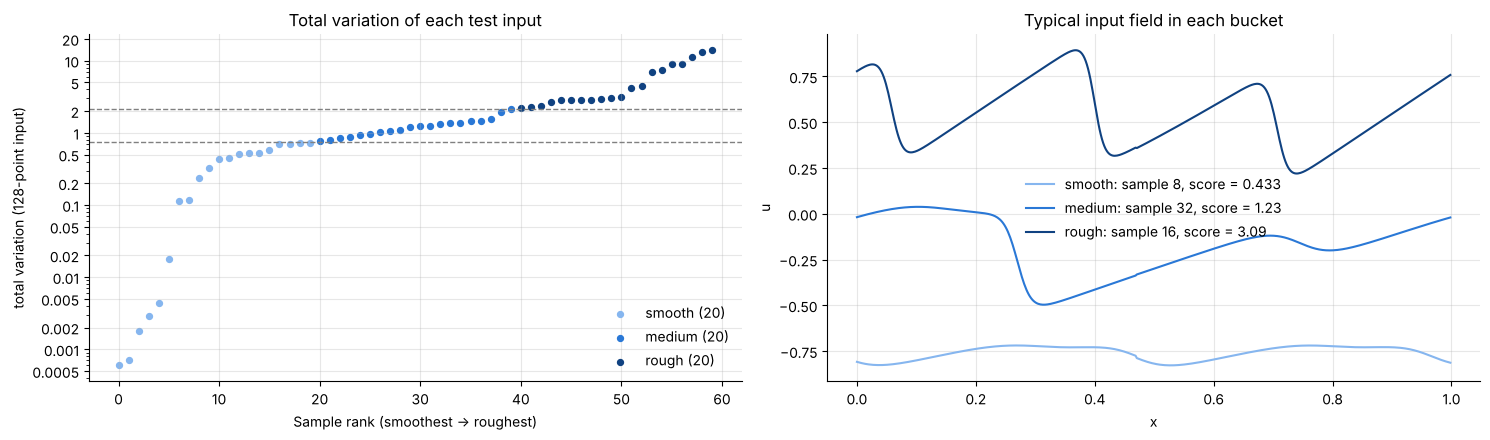

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# left: every input's score, smoothest to roughest, coloured by bucket
start = 0
for b in BUCKETS:
    r = np.sort(score[idx[b]])
    axes[0].scatter(np.arange(start, start + len(r)), r, s=18, color=BUCKET_COLORS[b], label=f"{b} ({len(r)})")
    start += len(r)
for e in edges:
    axes[0].axhline(e, color="gray", ls="--", lw=1)
axes[0].set_yscale("log"); log_axis(axes[0].yaxis)
axes[0].set_xlabel("Sample rank (smoothest → roughest)")
axes[0].set_ylabel(f"{BUCKET_MEASURE} (128-point input)")
axes[0].set_title(f"{BUCKET_MEASURE.capitalize()} of each test input")
axes[0].legend()

# right: the median input of each bucket, drawn on the 512-point grid
x512 = np.linspace(0, 1, 512, endpoint=False)
for b in BUCKETS:
    k = idx[b][np.argsort(score[idx[b]])[len(idx[b]) // 2]]
    axes[1].plot(x512, u_now[512][k], color=BUCKET_COLORS[b], label=f"{b}: sample {k}, score = {score[k]:.3g}")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].set_title("Typical input field in each bucket")
axes[1].legend()
plt.tight_layout(); plt.show()

## B. Results table and FNO-vs-CNN "wins"

*(From `bucked_based_eval`, cell 20.)* Mean relative $L^2$ error per bucket (×10⁻³), plus two growth columns:
- **difference** $e_{512} - e_{128}$: our test quantity;
- **ratio** $e_{512} / e_{128}$: the quantity `bucked_based_eval` used.

The second table counts, for each bucket and grid, how many of the 20 inputs the FNO predicts more accurately than the CNN.

In [6]:
rows = []
for m in ["FNO", "CNN", "Persistence"]:
    for b in BUCKETS:
        means = [err[m][N][idx[b]].mean() for N in RESOLUTIONS]
        rows.append({"model": m, "bucket": b, **{f"e{N}": 1e3 * v for N, v in zip(RESOLUTIONS, means)},
                     "difference e512-e128": 1e3 * (means[-1] - means[0]), "ratio e512/e128": means[-1] / means[0]})
display(pd.DataFrame(rows).round(3))

wins = pd.DataFrame({f"{N} pts": [f"{int(np.sum(err['FNO'][N][idx[b]] < err['CNN'][N][idx[b]]))}/20" for b in BUCKETS]
                     for N in RESOLUTIONS}, index=BUCKETS)
display(wins.rename_axis("inputs where the FNO beats the CNN"))

,model,bucket,e128,e256,e512,difference e512-e128,ratio e512/e128
0,FNO,smooth,0.426000,0.516000,0.548000,0.122000,1.286
1,FNO,medium,1.148000,1.361000,1.427000,0.279000,1.243
2,FNO,rough,10.563000,10.705000,10.718000,0.155000,1.015
3,CNN,smooth,0.246000,2.196000,3.238000,2.992000,13.172
4,CNN,medium,0.743000,10.276000,14.816000,14.073000,19.937
5,CNN,rough,7.929000,39.591000,57.224998,49.296001,7.217
6,Persistence,smooth,4.232000,4.231000,4.231000,-0.001000,1.000
7,Persistence,medium,19.153999,19.153000,19.153000,-0.002000,1.000
8,Persistence,rough,74.217003,74.261002,74.273003,0.056000,1.001


,128 pts,256 pts,512 pts
inputs where the FNO beats the CNN,,,
smooth,3/20,14/20,14/20
medium,1/20,20/20,20/20
rough,1/20,20/20,20/20


**Reading it.** At 128 points the CNN is the more accurate model on most inputs. On the finer grids the FNO wins on
nearly every input, because the CNN's error explodes and the FNO's barely moves.

## C. How each bucket's error changes as the grid gets finer

*(From `bucked_based_eval`, Plot B.)* **Top row:** the ratio $e_N / e_{128}$, as in `bucked_based_eval`
(1.0 = no change). **Bottom row:** the difference $e_N - e_{128}$, our test quantity (0 = no change).

The two rows tell different stories for the CNN, which is why we use the difference. In the ratio, the CNN's *rough*
inputs seem to grow the *least*. But their error at 128 points is already large, and dividing by it hides the fact that
their error grows by far the most in absolute terms (bottom row). The ratio mixes up "how big the error was" with
"how much it grew".

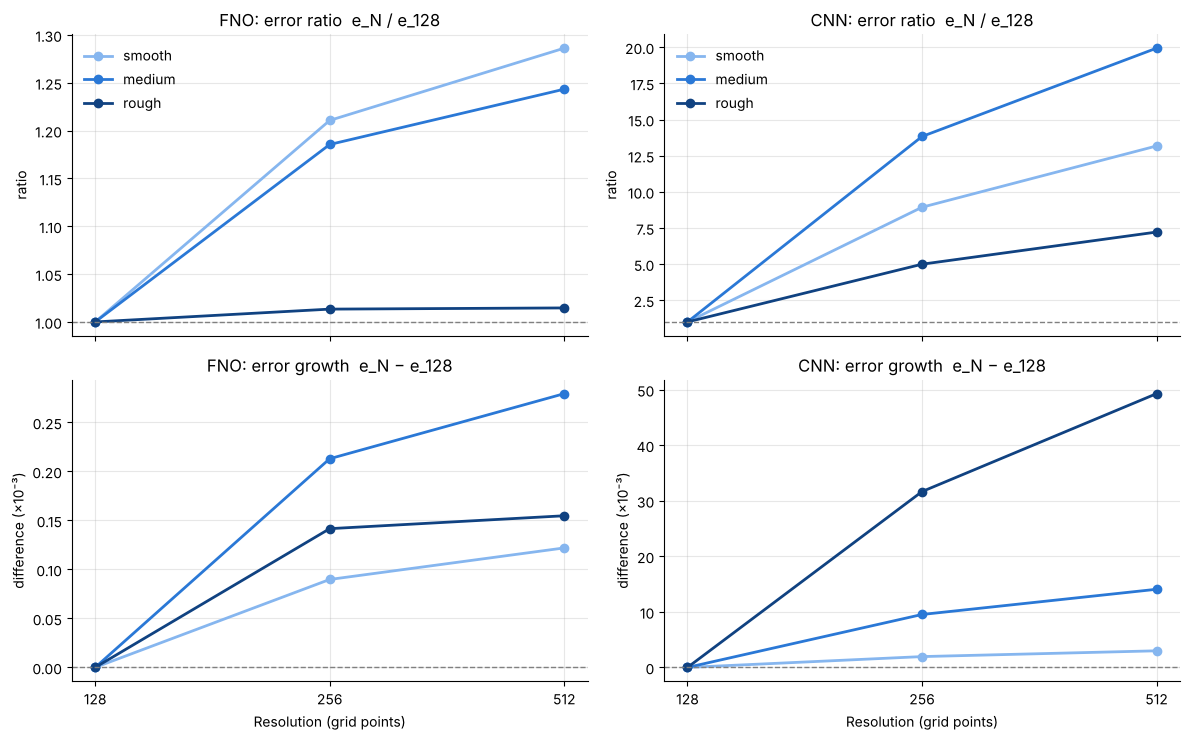

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for col, m in enumerate(["FNO", "CNN"]):
    for b in BUCKETS:
        base = err[m][128][idx[b]].mean()
        ratio = [err[m][N][idx[b]].mean() / base for N in RESOLUTIONS]
        diff = [1e3 * (err[m][N][idx[b]].mean() - base) for N in RESOLUTIONS]
        axes[0, col].plot(RESOLUTIONS, ratio, "o-", color=BUCKET_COLORS[b], lw=2, label=b)
        axes[1, col].plot(RESOLUTIONS, diff, "o-", color=BUCKET_COLORS[b], lw=2, label=b)
    axes[0, col].axhline(1, color="gray", ls="--", lw=1); axes[1, col].axhline(0, color="gray", ls="--", lw=1)
    axes[0, col].set_title(f"{m}: error ratio  e_N / e_128"); axes[1, col].set_title(f"{m}: error growth  e_N − e_128")
    axes[0, col].set_ylabel("ratio"); axes[1, col].set_ylabel("difference (×10⁻³)")
    for r in range(2):
        axes[r, col].set_xscale("log", base=2); axes[r, col].set_xticks(RESOLUTIONS)
        axes[r, col].set_xticklabels([str(N) for N in RESOLUTIONS]); axes[r, col].minorticks_off()
    axes[1, col].set_xlabel("Resolution (grid points)")
    axes[0, col].legend()
plt.tight_layout(); plt.show()

**Reading it.** Bottom row: the CNN's growth fans out by roughness (rough ≫ medium ≫ smooth). The FNO's lines are
flat and bunched together near 0. Note the very different y-scales: the FNO's whole range is smaller than the CNN's
smooth bucket alone.

## D. Error per bucket against persistence

*(From `bucked_based_eval`, cell 26.)* **Left:** mean error at each grid for FNO, CNN and persistence (log scale).
**Right:** growth $e_N - e_{128}$ with 95% bootstrap intervals over the 12 test trajectories. The original showed the
ratio here; we show the difference for the reason given in C.

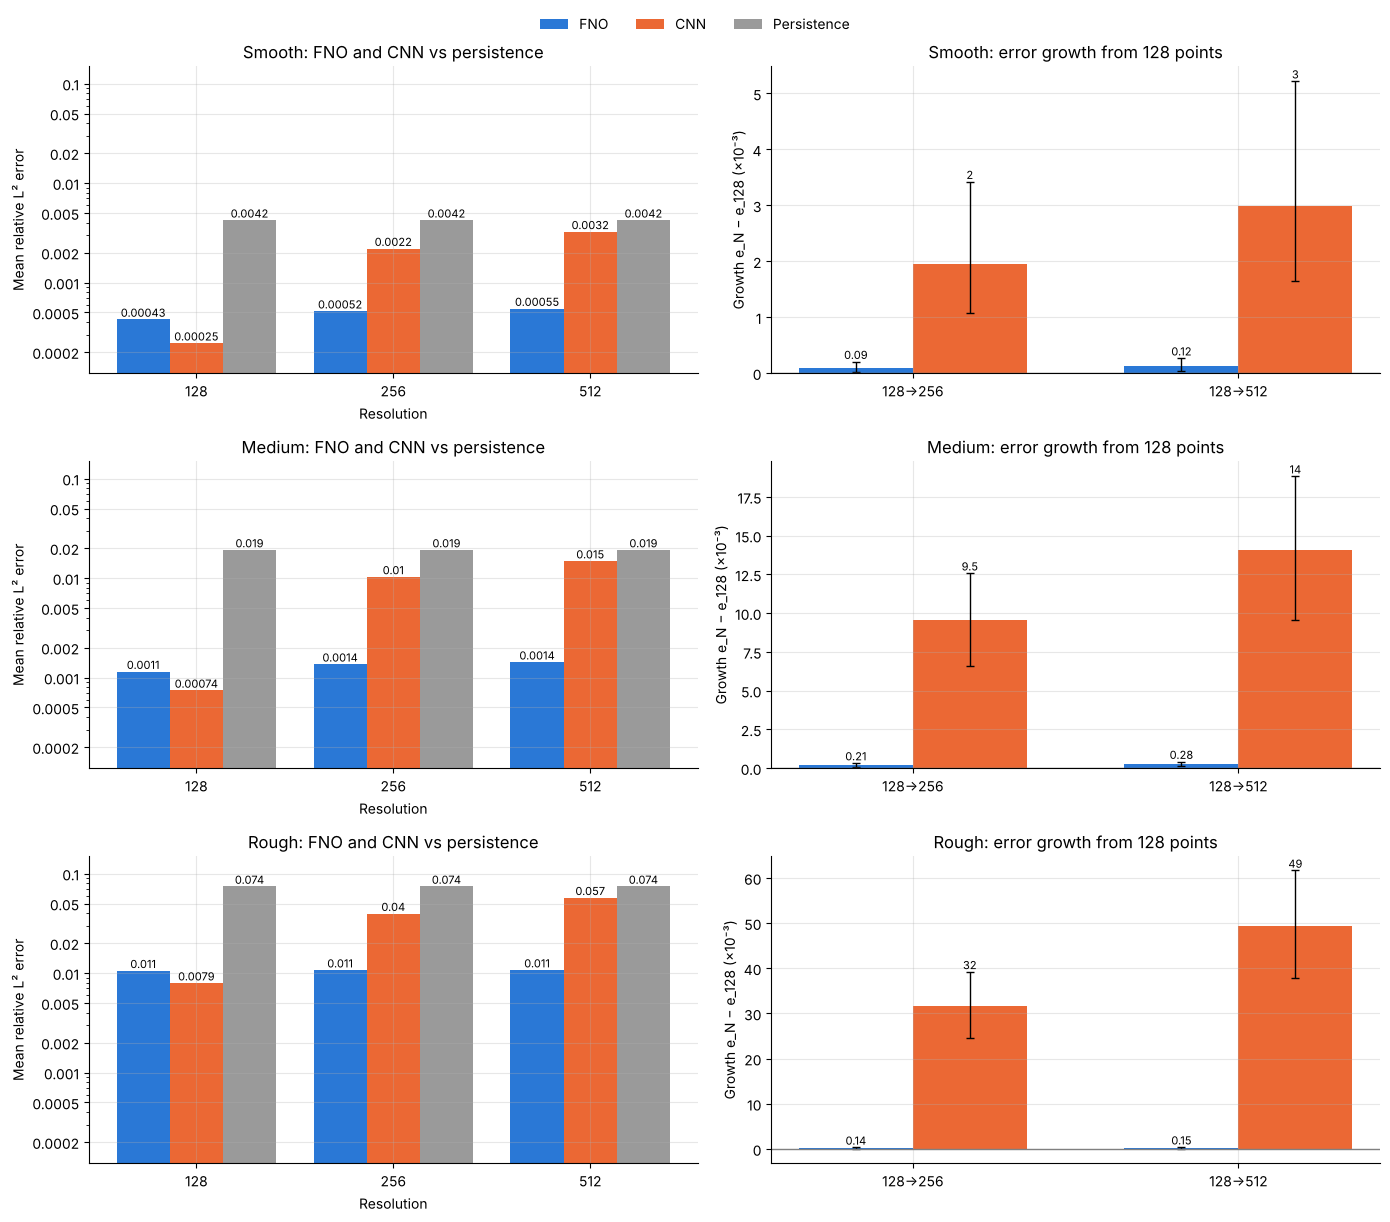

In [8]:
traj = np.arange(60) // 5
def boot_ci(values, n_boot=2000, seed=0):
    # 95% interval of the mean of `values` (one per example in a bucket), resampling whole trajectories
    rng = np.random.default_rng(seed); t = traj[values.index]; v = values.values
    groups = [v[t == g] for g in np.unique(t)]
    means = [np.concatenate([groups[i] for i in rng.choice(len(groups), len(groups))]).mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])

all_means = [err[m][N][idx[b]].mean() for m in COLORS for b in BUCKETS for N in RESOLUTIONS]
fig, axes = plt.subplots(len(BUCKETS), 2, figsize=(14, 12))
for row, b in enumerate(BUCKETS):
    ax = axes[row, 0]                                   # left: mean error at each resolution
    x, w = np.arange(len(RESOLUTIONS)), 0.27
    for k, m in enumerate(["FNO", "CNN", "Persistence"]):
        xs = x + (k - 1) * w
        means = [err[m][N][idx[b]].mean() for N in RESOLUTIONS]
        ax.bar(xs, means, w, color=COLORS[m], label=m)
        for xi, v in zip(xs, means):
            ax.text(xi, v, f"{v:.2g}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels([str(N) for N in RESOLUTIONS]); ax.set_xlabel("Resolution")
    ax.set_ylabel("Mean relative L² error"); ax.set_yscale("log")
    ax.set_ylim(min(all_means) * 0.5, max(all_means) * 2); log_axis(ax.yaxis)
    ax.set_title(f"{b.capitalize()}: FNO and CNN vs persistence")

    ax = axes[row, 1]                                   # right: growth with bootstrap intervals
    x, w = np.arange(len(RESOLUTIONS) - 1), 0.35
    for k, m in enumerate(["FNO", "CNN"]):
        xs = x + (k - 0.5) * w
        for xi, N in zip(xs, RESOLUTIONS[1:]):
            g = pd.Series(err[m][N] - err[m][128]).iloc[idx[b]]
            lo, hi = boot_ci(g)
            ax.bar(xi, 1e3 * g.mean(), w, color=COLORS[m], label=m if xi == xs[0] else None)
            ax.errorbar(xi, 1e3 * g.mean(), yerr=[[1e3 * max(g.mean() - lo, 0)], [1e3 * max(hi - g.mean(), 0)]],
                        color="k", capsize=3, lw=1)
            ax.text(xi, 1e3 * max(hi, g.mean()), f"{1e3 * g.mean():.2g}", ha="center", va="bottom", fontsize=8)
    ax.axhline(0, color="gray", lw=1)
    ax.set_xticks(x); ax.set_xticklabels([f"128→{N}" for N in RESOLUTIONS[1:]])
    ax.set_ylabel("Growth e_N − e_128 (×10⁻³)"); ax.set_title(f"{b.capitalize()}: error growth from 128 points")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(); plt.show()

**Reading it.** Left: the FNO stays far below persistence on every grid in every bucket, so it is a useful model
everywhere. The CNN falls back towards persistence on the finer grids. Right: the CNN's growth increases strongly with
roughness. The FNO's bars are tiny and their intervals overlap across buckets.

## E. One typical prediction per bucket, at all three resolutions

*(From `bucked_based_eval`, Plot C.)* For the median input of each bucket: the input (dotted grey), the true next
state (black), and the FNO and CNN predictions (dashed). The title gives each model's error on that input.
Predictions come from seed `EXAMPLE_SEED`.

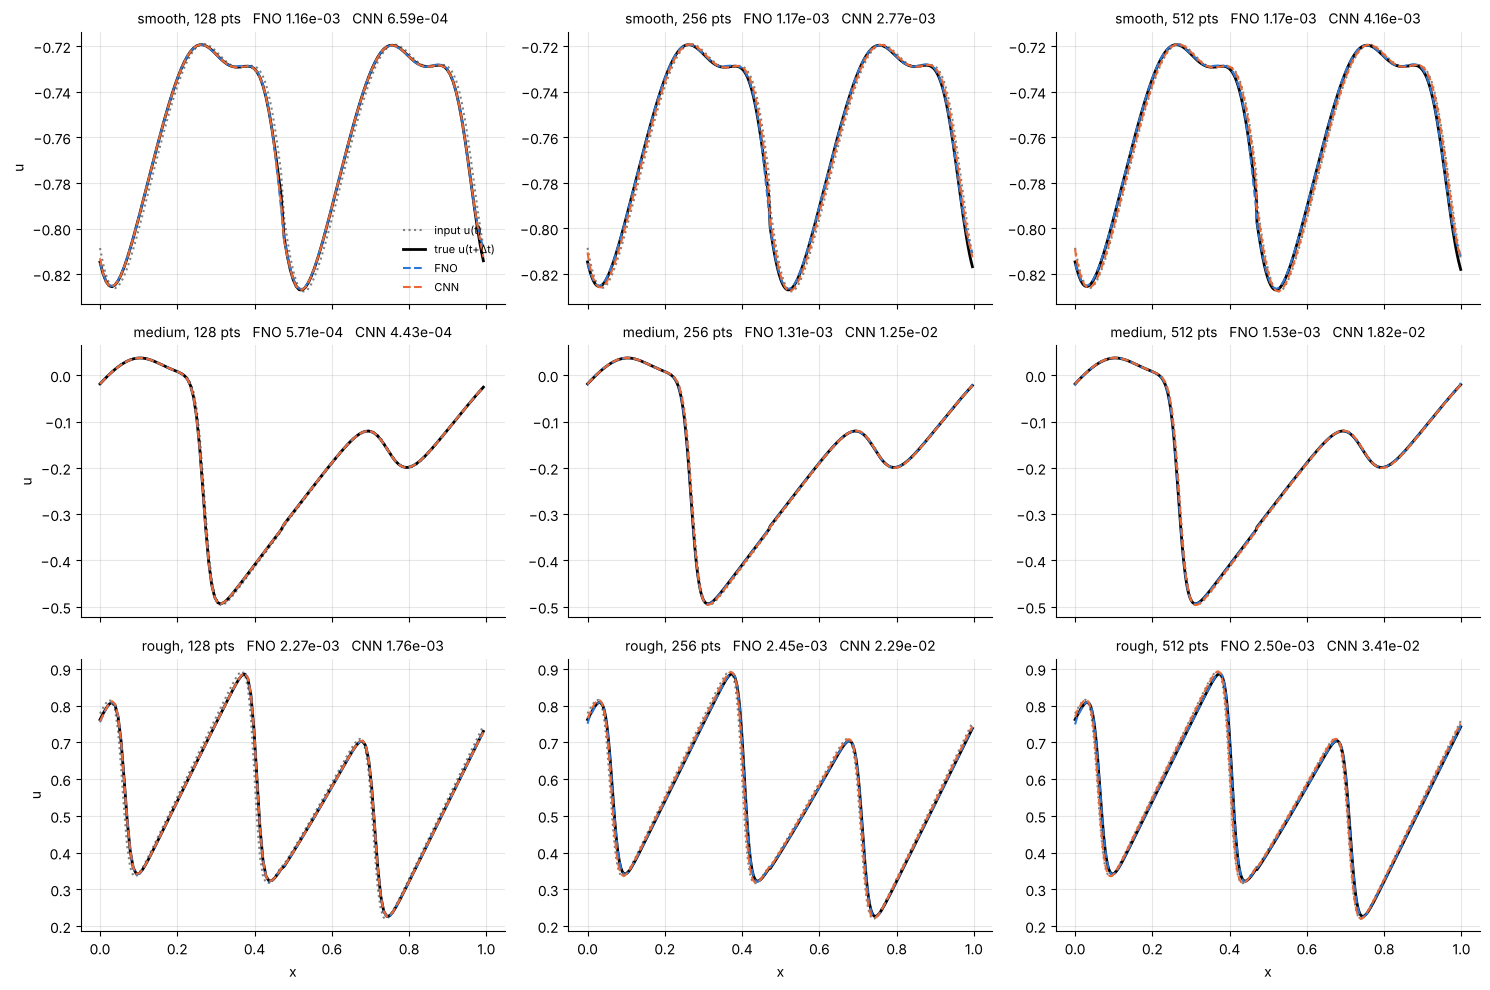

In [9]:
examples = {b: idx[b][np.argsort(score[idx[b]])[len(idx[b]) // 2]] for b in BUCKETS}   # median input per bucket
S = EXAMPLE_SEED
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for i, b in enumerate(BUCKETS):
    s = examples[b]
    for j, N in enumerate(RESOLUTIONS):
        ax = axes[i, j]
        xg = np.linspace(0, 1, N, endpoint=False)
        e_f = rel_l2(pred["FNO"][S][N][[s]], u_next[N][[s]])[0]
        e_c = rel_l2(pred["CNN"][S][N][[s]], u_next[N][[s]])[0]
        ax.plot(xg, u_now[N][s], ":", color="gray", label="input u(t)")
        ax.plot(xg, u_next[N][s], "-", color="k", lw=2, label="true u(t+Δt)")
        ax.plot(xg, pred["FNO"][S][N][s], "--", color=COLORS["FNO"], label="FNO")
        ax.plot(xg, pred["CNN"][S][N][s], "--", color=COLORS["CNN"], label="CNN")
        ax.set_title(f"{b}, {N} pts   FNO {e_f:.2e}   CNN {e_c:.2e}", fontsize=10)
    axes[i, 0].set_ylabel("u")
for ax in axes[-1]:
    ax.set_xlabel("x")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading it.** At this scale all predictions lie on top of the true solution. The differences are a fraction of a
percent, too small to see, which is why the next figure plots the errors directly.

## F. Where the errors are: prediction − truth along x

*(From `bucked_based_eval`, cell 25.)* The same inputs as in E, but showing each model's error
$\hat u - u$ instead of the fields. Rows share a y-axis, so you can compare the grids directly.

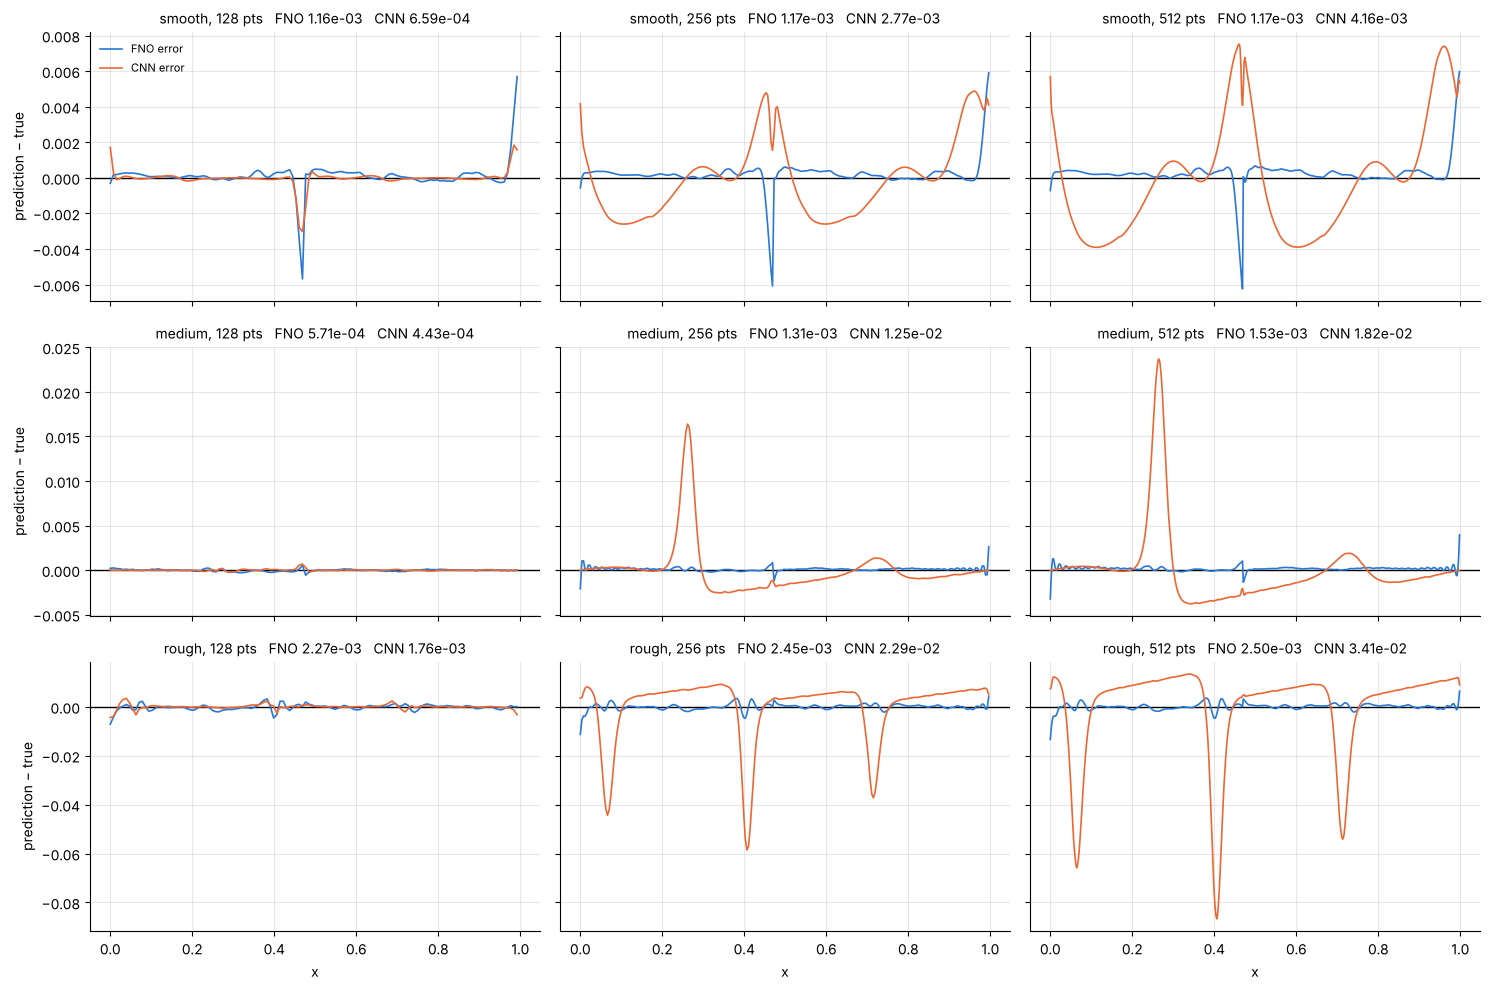

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True, sharey="row")
for i, b in enumerate(BUCKETS):
    s = examples[b]
    for j, N in enumerate(RESOLUTIONS):
        ax = axes[i, j]
        xg = np.linspace(0, 1, N, endpoint=False)
        e_f = rel_l2(pred["FNO"][S][N][[s]], u_next[N][[s]])[0]
        e_c = rel_l2(pred["CNN"][S][N][[s]], u_next[N][[s]])[0]
        ax.axhline(0, color="k", lw=1)
        ax.plot(xg, pred["FNO"][S][N][s] - u_next[N][s], color=COLORS["FNO"], lw=1.2, label="FNO error")
        ax.plot(xg, pred["CNN"][S][N][s] - u_next[N][s], color=COLORS["CNN"], lw=1.2, label="CNN error")
        ax.set_title(f"{b}, {N} pts   FNO {e_f:.2e}   CNN {e_c:.2e}", fontsize=10)
    axes[i, 0].set_ylabel("prediction − true")
for ax in axes[-1]:
    ax.set_xlabel("x")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading it. Three things to notice:**
1. **The CNN's error changes shape on finer grids.** At 128 points it is small and local. At 256 and 512 points it
   becomes a large, smooth wave. Its kernel now covers a smaller piece of the domain, so it gets the dynamics wrong
   everywhere, not just at fronts.
2. **The FNO's error barely changes between grids**, but on finer grids small **wiggles** appear: fine-scale content
   that the true solution does not have.
3. **The FNO has spikes at the very edges of the domain** (x ≈ 0 and x ≈ 1). For some inputs they are there already at
   128 points (smooth example); on the finer grids they show up for more inputs (medium example). The CNN has no such
   spikes. Figure H looks at this over all inputs.

## G. Error of every input against its roughness

*(From `bucked_based_eval`, cell 27.)* Each dot is one test input. This shows the same result as the buckets but
without any cut-offs: if the FNO's error depended on roughness *differently on different grids*, the blue cloud would
change shape from panel to panel. The orange crosses are persistence (the true one-step change).

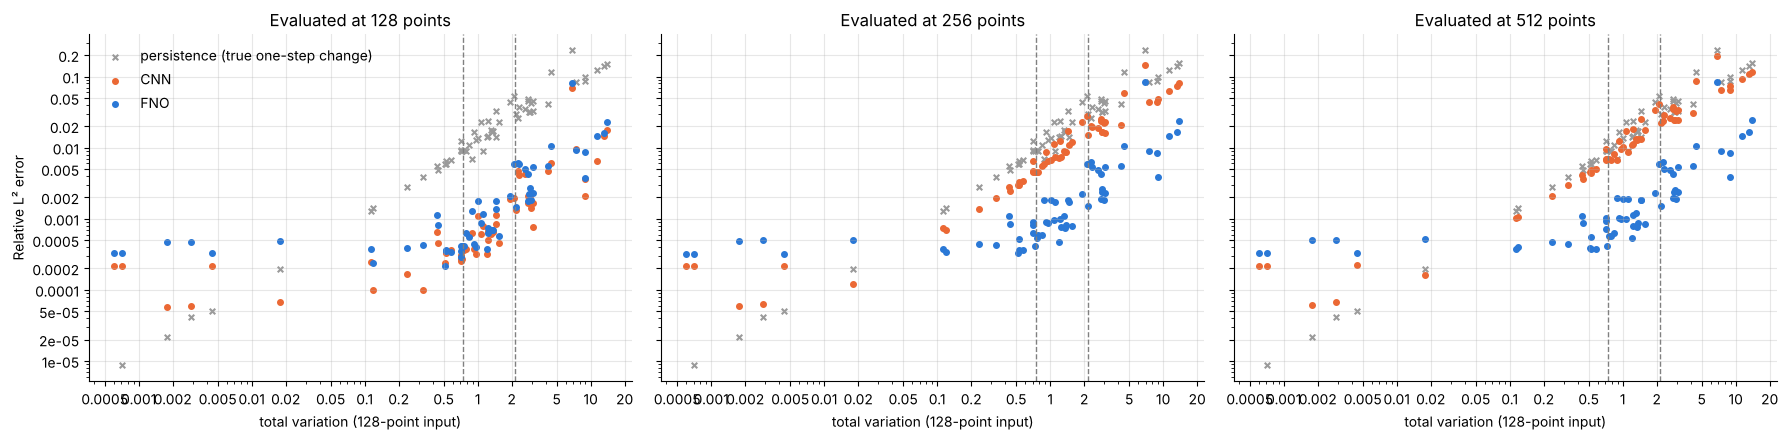

In [11]:
STYLE = {"FNO": dict(color=COLORS["FNO"], marker="o", label="FNO"),
         "CNN": dict(color=COLORS["CNN"], marker="o", label="CNN"),
         "Persistence": dict(color="#9a9a9a", marker="x", label="persistence (true one-step change)")}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, N in zip(axes, RESOLUTIONS):
    for m in ["Persistence", "CNN", "FNO"]:
        ax.scatter(score, err[m][N], s=16, **STYLE[m])
    for e in edges:
        ax.axvline(e, color="gray", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); log_axis(ax.xaxis); log_axis(ax.yaxis)
    ax.set_xlabel(f"{BUCKET_MEASURE} (128-point input)"); ax.set_title(f"Evaluated at {N} points")
axes[0].set_ylabel("Relative L² error"); axes[0].legend()
plt.tight_layout(); plt.show()

**Reading it.** From 128 to 512 points the CNN cloud (orange) rises towards persistence, most of all on the right
(rough inputs). The FNO cloud (blue) keeps almost exactly the same shape and height in all three panels.

---
## H. Where does the FNO's error sit? (new)

Figure F showed spikes at the domain edges. Here we measure them over all 60 inputs and all 3 seeds:
- **Left:** the squared error at each position $x$, averaged over all inputs and divided by the mean squared size of
  the true field, at 128 and 512 points. The grey bands are the 3% of the domain nearest each edge.
- **First table:** for each bucket, the share of the FNO's squared error that falls inside those bands (they are only
  6% of the domain), at 128 and 512 points, averaged over the 3 seeds.
- **Second table:** the FNO's growth $e_{512} - e_{128}$ per bucket, on the full domain and with the edge points removed.

**A likely cause.** The FNO's second input channel is the position $x \in [0, 1)$. The field is periodic and wraps
around smoothly, but $x$ **jumps from almost 1 back to 0** at the edge. In Fourier space that jump is spread over all
wavenumbers, and its fine-scale part looks different on each grid. This is an interpretation, not something we tested
directly. The obvious test is to give the FNO a periodic position encoding ($\sin 2\pi x$, $\cos 2\pi x$) or no
position input at all.

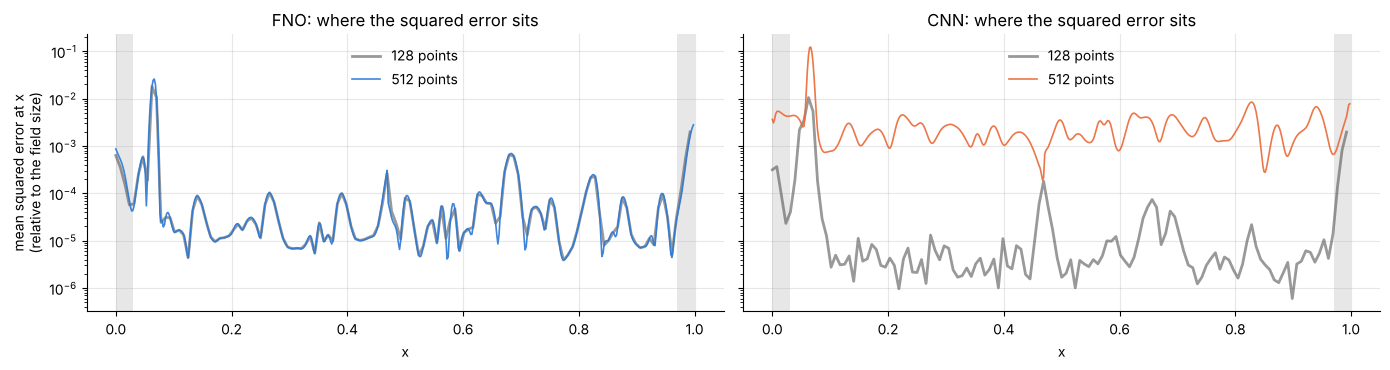

grid,128,512
FNO: share of squared error in the edge bands (6% of the domain),,
smooth,0.50,0.49
medium,0.04,0.08
rough,0.10,0.11


,full domain,edge bands removed
FNO growth e512 − e128 (×10⁻³),,
smooth,0.122,0.066
medium,0.279,0.124
rough,0.155,0.065


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
rows = []
for ax, m in zip(axes, ["FNO", "CNN"]):
    for N, ls in [(128, "-"), (512, "-")]:
        xg = np.arange(N) / N
        e2 = np.mean([(pred[m][s][N] - u_next[N]) ** 2 for s in range(3)], axis=0)   # (60, N), seed-averaged
        density = e2.mean(0) / (u_next[N] ** 2).mean()                              # relative squared error at each x
        ax.plot(xg, density, lw=1.2 if N == 512 else 2, alpha=0.9 if N == 512 else 0.6,
                color=COLORS[m] if N == 512 else "#555555", label=f"{N} points")
        edge = (xg < 0.03) | (xg > 0.97)
        if m == "FNO":
            for b in BUCKETS:
                shares = [((pred[m][s][N] - u_next[N])[idx[b]][:, edge] ** 2).sum()
                          / ((pred[m][s][N] - u_next[N])[idx[b]] ** 2).sum() for s in range(3)]
                rows.append(dict(bucket=b, grid=N, share=np.mean(shares)))
    for lo, hi in [(0, 0.03), (0.97, 1)]:
        ax.axvspan(lo, hi, color="#d0d0d0", alpha=0.5, lw=0)
    ax.set_yscale("log"); ax.set_xlabel("x"); ax.set_title(f"{m}: where the squared error sits"); ax.legend()
axes[0].set_ylabel("mean squared error at x\n(relative to the field size)")
plt.tight_layout(); plt.show()

display(pd.DataFrame(rows).pivot(index="bucket", columns="grid", values="share").loc[BUCKETS]
        .round(2).rename_axis("FNO: share of squared error in the edge bands (6% of the domain)"))

def interior_err(p, y, N):
    keep = ~((np.arange(N) / N < 0.03) | (np.arange(N) / N > 0.97))
    return np.linalg.norm((p - y)[:, keep], axis=1) / np.linalg.norm(y[:, keep], axis=1)
growth = {}
for name, f in [("full domain", lambda p, y, N: rel_l2(p, y)), ("edge bands removed", interior_err)]:
    e = {N: np.mean([f(pred["FNO"][s][N], u_next[N], N) for s in range(3)], axis=0) for N in (128, 512)}
    growth[name] = [1e3 * (e[512][idx[b]].mean() - e[128][idx[b]].mean()) for b in BUCKETS]
display(pd.DataFrame(growth, index=BUCKETS).round(3).rename_axis("FNO growth e512 − e128 (×10⁻³)"))

**Reading it.**
- **Left panel.** The FNO's largest error peak is at x ≈ 0.06, where several rough inputs have a steep front (the CNN
  has a peak there too). Apart from that, the FNO's error **rises sharply at both edges**, which the CNN's does not.
- For **smooth** inputs, about **half** of the FNO's squared error sits in the edge bands, which are only 6% of the
  domain. For medium and rough inputs the share is much lower (≈5–10%), because their error is dominated by the fronts.
- Removing the edge bands **roughly halves the FNO's growth in every bucket**. So about half of its small
  non-invariance is an edge effect. What remains is still small and roughness-independent.
- **For the report:** this is a concrete, model-side source of the FNO's small error growth, separate from roughness.
  It fits in the analysis next to the spurious fine-scale content (figure I), with a periodic position encoding as the
  natural fix.

---
## I. Error spectrum at 512 points (new, Part 2)

This is the picture behind notebook 03's frequency split. For each bucket we Fourier-transform the 512-point error of
the FNO and average its energy at each wavenumber $k$ (divided by the size of the true field, so the energies add up to
the squared relative error). For comparison:
- **grey:** the spectrum of the **true next state** itself. Above the training Nyquist (dashed line), a model that adds
  *no* fine detail has exactly this much error there (the truncation reference).
- **blue:** the FNO's error spectrum.

Right of the dashed line: **blue below grey** = the FNO recovers some real fine-scale detail; **blue above grey** = it
adds wrong fine-scale detail. Top row: FNO trained at 128 points. Bottom row: trained at 32 points, where much more
detail is unseen.

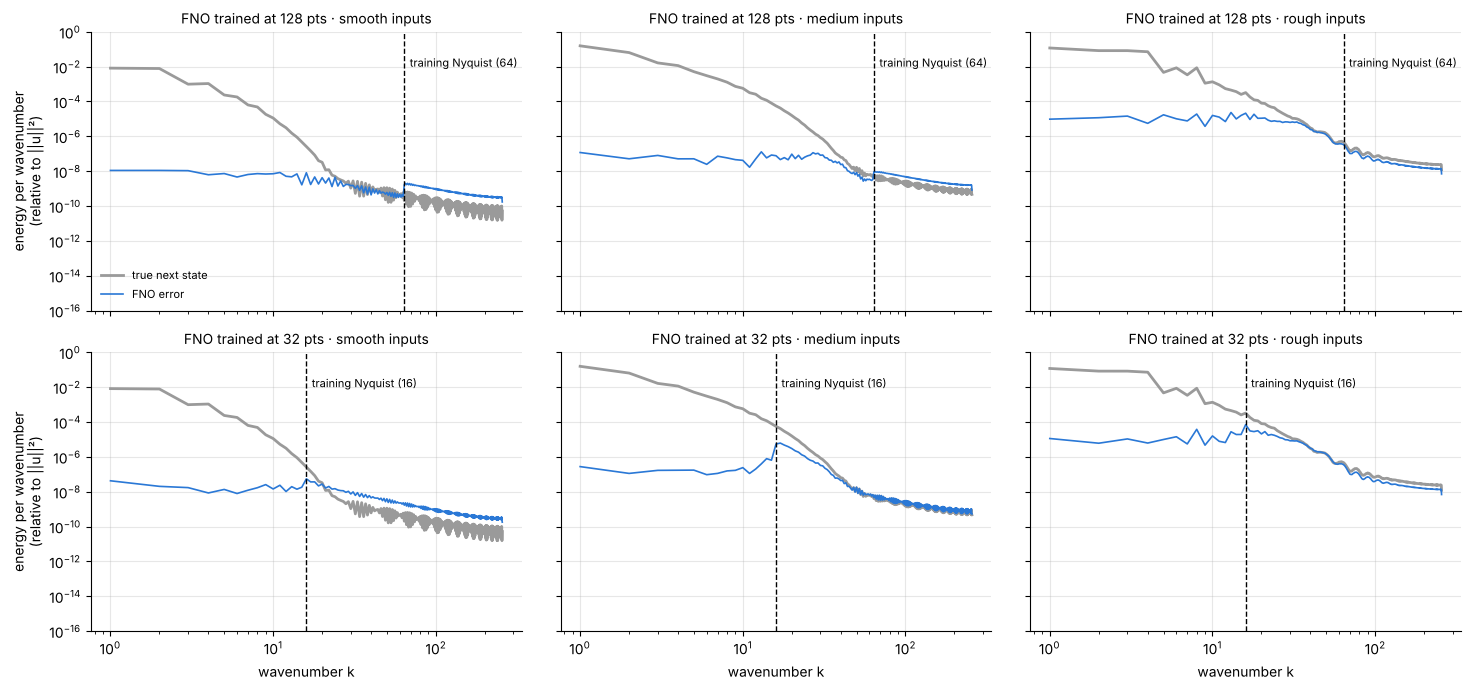

In [13]:
def spectrum(v, y):
    # energy per wavenumber of each row of v, divided by ||y||^2 (so it sums to the squared relative error)
    F = np.abs(np.fft.rfft(v.astype(np.float64), axis=1)) ** 2
    w = np.ones(F.shape[1]); w[1:-1] = 2                     # count +k and -k (not k = 0 or Nyquist)
    return w * F / v.shape[1] / (np.linalg.norm(y.astype(np.float64), axis=1, keepdims=True) ** 2)

y = u_next[512]; k = np.arange(257)
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for r, n_train in enumerate([128, 32]):
    p = [predict(load_model("fno", n_train, s), u_now[512]) for s in range(3)]
    for c, b in enumerate(BUCKETS):
        ax = axes[r, c]
        e_spec = np.mean([spectrum(p[s] - y, y)[idx[b]].mean(0) for s in range(3)], axis=0)
        y_spec = spectrum(y, y)[idx[b]].mean(0)
        ax.plot(k[1:], y_spec[1:], color="#9a9a9a", lw=2, label="true next state")
        ax.plot(k[1:], e_spec[1:], color=COLORS["FNO"], lw=1.2, label="FNO error")
        ax.axvline(n_train // 2, color="k", ls="--", lw=1)
        ax.text(n_train // 2 * 1.08, 1e-2, f"training Nyquist ({n_train // 2})", fontsize=8)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-16, 1)
        ax.set_title(f"FNO trained at {n_train} pts · {b} inputs", fontsize=10)
    axes[r, 0].set_ylabel("energy per wavenumber\n(relative to ||u||²)")
for ax in axes[-1]:
    ax.set_xlabel("wavenumber k")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading it.** Look to the right of the dashed line.
- **Smooth inputs:** the true field has almost nothing there (grey drops steeply), but the FNO's error does not drop
  with it. It produces fine-scale content that should not be there. This is the spurious content behind its small
  growth, and the edge spikes of figure H are one source of it (a jump puts energy at all wavenumbers).
- **Rough inputs:** the true field has a lot of fine-scale energy, and the FNO's error stays **below** the grey curve
  for a good stretch past the Nyquist line, especially when trained at 32 points. It reproduces part of detail it was
  never trained on. That is notebook 03's "recovered 23–49%".

## J. Zoom on one rough front: FNO trained at 32 points, evaluated at 512 (new, Part 2)

The most direct picture of genuine transfer. We take the median **rough** input, find its steepest front, and zoom in.
- **black:** the true next state on 512 points;
- **orange dots:** the FNO's prediction on its 32-point training grid, joined by straight lines. Lines between coarse
  points are all you would get by predicting at 32 points and interpolating;
- **blue:** the same FNO run directly on the 512-point input.

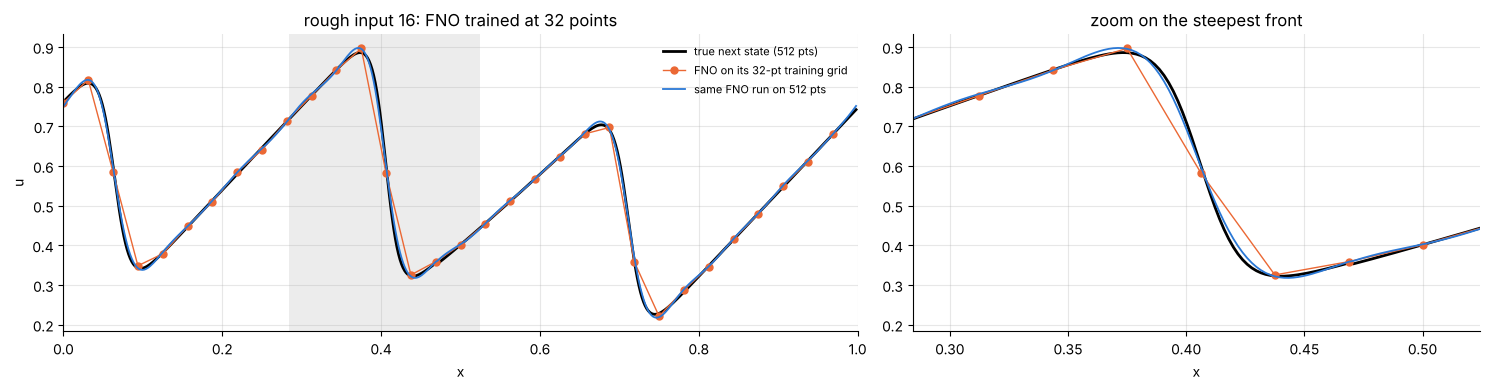

error on 512 points: FNO run directly 0.0097 | 32-point prediction joined by straight lines 0.0369


In [14]:
s = examples["rough"]
fno32 = load_model("fno", 32, EXAMPLE_SEED)
p32, p512 = predict(fno32, u_now[32][[s]])[0], predict(fno32, u_now[512][[s]])[0]
x32, x512 = np.arange(32) / 32, np.arange(512) / 512
front = x512[np.argmax(np.abs(np.diff(u_next[512][s], append=u_next[512][s][0])))]   # steepest point
lo, hi = front - 0.12, front + 0.12

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw=dict(width_ratios=[1.4, 1]))
for ax, (a, z) in zip(axes, [((0, 1), False), ((lo, hi), True)]):
    ax.plot(x512, u_next[512][s], color="k", lw=2, label="true next state (512 pts)")
    ax.plot(x32, p32, "o-", color=COLORS["CNN"], ms=5, lw=1, label="FNO on its 32-pt training grid")
    ax.plot(x512, p512, color=COLORS["FNO"], lw=1.3, label="same FNO run on 512 pts")
    ax.set_xlim(*a); ax.set_xlabel("x")
    if z:
        ax.set_title("zoom on the steepest front")
axes[0].axvspan(lo, hi, color="#d0d0d0", alpha=0.4, lw=0); axes[0].set_ylabel("u"); axes[0].legend(fontsize=8)
axes[0].set_title(f"rough input {s}: FNO trained at 32 points")
plt.tight_layout(); plt.show()

e_direct = rel_l2(p512[None], u_next[512][[s]])[0]
e_interp = rel_l2(np.interp(x512, np.append(x32, 1), np.append(p32, p32[0]))[None], u_next[512][[s]])[0]
print(f"error on 512 points: FNO run directly {e_direct:.4f} | 32-point prediction joined by straight lines {e_interp:.4f}")

**Reading it.** Between the coarse points, straight lines cut the corners of the front. The FNO run directly on 512
points follows the true front much more closely, although it never saw a 512-point field in training. It uses the
extra detail in the fine input. The printed errors put a number on it.

---
## Summary of what the figures show

1. **The main result (C, D, G):** the CNN's error grows on finer grids, and much more for rough inputs. The FNO's error
   barely moves in any bucket.
2. **Where the FNO's small growth comes from (F, H, I):** spurious fine-scale content, a large part of it concentrated
   at the **domain edges**, probably from the non-periodic position input. It is not tied to roughness.
3. **Not "nothing to fail on" (I, J):** when the fine grid holds detail the model never saw, the FNO reproduces part of it.